# Convolutional Neural Network — Mimariler

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gorkenvm/Presentations/blob/main/cnn2/cnn2_ders.ipynb)

> Bu defterin ilk kısmı **önceki dersin hızlı özetidir**. Asıl konumuz *Chapter 4: CNN Architectures* ve sonrasıdır.

---
# 1. Convolutional Neural Network (CNN) Mimarisi

Görüntüyü katman katman süzerek **önce özellik çıkaran, sonra bu özelliklere bakıp sınıflandıran** bir sinir ağıdır.

**Mimarideki temel parçalar**

| Katman | Ne yapar? |
|---|---|
| **Convolution (Evrişim)** | Filtre görüntü üzerinde gezer, öznitelik haritası çıkarır |
| **Aktivasyon (ReLU)** | Doğrusal olmayanlık katar |
| **Pooling** | Boyutu küçültür, önemli bilgiyi korur |
| **Flatten** | Matrisleri tek bir vektöre serer |
| **Fully Connected (Dense)** | Öznitelikleri birleştirir, kararı verir |
| **Softmax** | Sınıf olasılıklarını üretir |

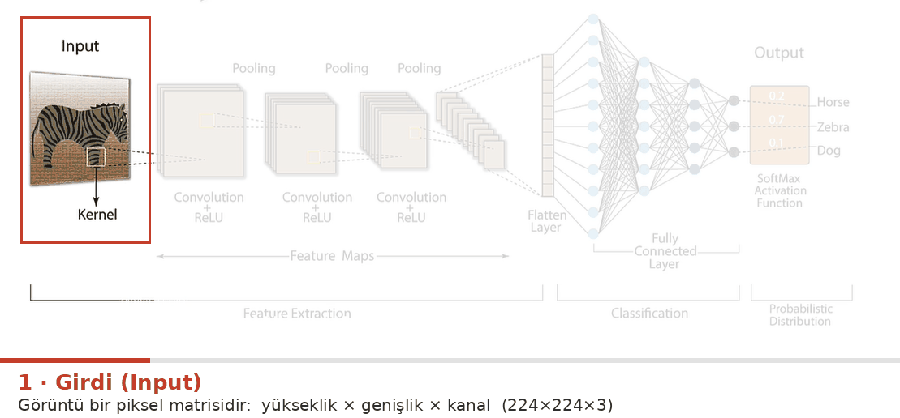

<sub>Girdiden çıktıya akış: **Conv → ReLU → Pooling** bloğu tekrarlanır, ardından **Flatten → Dense → Softmax**.</sub>

---
## 1.1 Görüntü bilgisayara nasıl görünür?

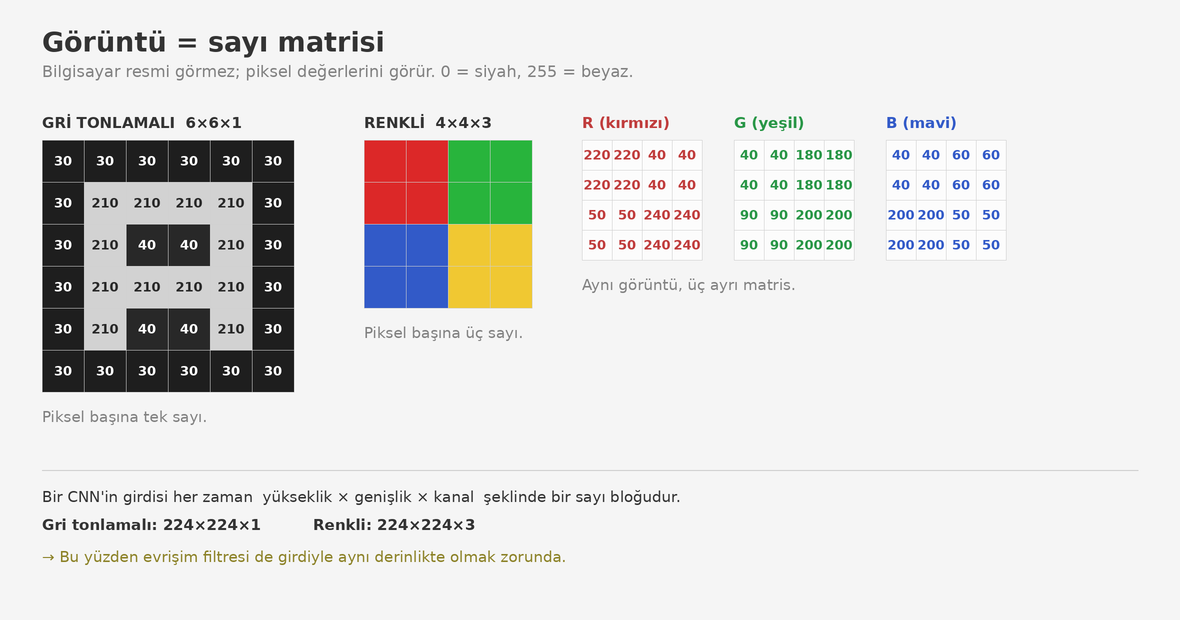

### Şimdi bu sayıları gerçek bir fotoğrafta görelim

Aşağıdaki hücreler indirme yapmaz, internet gerektirmez — matplotlib ile birlikte
gelen örnek fotoğrafı kullanır.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import cbook, patches
import numpy as np

# Görseli yükleme
resim = plt.imread(cbook.get_sample_data("grace_hopper.jpg"))

print("Şekil (yükseklik, genişlik, kanal):", resim.shape)
print("Veri tipi:", resim.dtype, "| en küçük değer:", resim.min(),
      "| en büyük değer:", resim.max())
print("Toplam kaç sayı:", resim.size)

# Odaklanılacak alan parametreleri
satir, sutun, n = 500, 392, 8

# Yan yana iki grafik oluşturalım
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

# 1. Sol Grafik: Tam resim ve kırmızı işaretleyici
ax1.imshow(resim)

rect = patches.Rectangle((sutun, satir), n, n,
                        edgecolor="red", facecolor="none", lw=2)
ax1.add_patch(rect)

# Küçük kutu uzaktan zor seçildiği için bir de ok koyalım
ax1.annotate('', xy=(sutun, satir), xytext=(sutun - 100, satir - 100),
             arrowprops=dict(facecolor='yellow', edgecolor='red',
                             shrink=0.05, width=2, headwidth=8))

ax1.set_title("Orijinal Resim ve Seçili Alan")
ax1.axis("off")

# 2. Sağ Grafik: Yakınlaştırılmış 8x8 piksel alanı
kirpilan_bolge = resim[satir:satir+n, sutun:sutun+n]
ax2.imshow(kirpilan_bolge)
ax2.set_title(f"{n}x{n} Yakınlaştırılmış Alan")

plt.tight_layout()
plt.show()

Fotoğraf **600 × 512 × 3** çıktı: 600 satır, 512 sütun, 3 kanal.
Toplam **921.600 sayı** — tek bir fotoğraf için.

Sağdaki 8×8'lik parça üniformadaki **madalya şeritlerinin** üzerine denk geldi.
Şimdi o parçanın içindeki sayılara tek tek bakalım.

In [ ]:
parca = resim[satir:satir + n, sutun:sutun + n]

print("Parçanın şekli:", parca.shape)
print("Sol üst pikselin değeri:", parca[0, 0], " → (R, G, B)")

sekil, eksenler = plt.subplots(1, 4, figsize=(16, 4.6))

eksenler[0].imshow(parca)
eksenler[0].set_title(f"Parça (renkli)\n{n}x{n}x3")

for k, (ad, renk_haritasi) in enumerate([("R (kırmızı)", "Reds"),
                                         ("G (yeşil)",   "Greens"),
                                         ("B (mavi)",    "Blues")]):
    eksen = eksenler[k + 1]
    kanal = parca[:, :, k]
    eksen.imshow(kanal, cmap=renk_haritasi, vmin=0, vmax=255)
    for r in range(n):
        for c in range(n):
            eksen.text(c, r, kanal[r, c], ha="center", va="center", fontsize=8,
                       color="white" if kanal[r, c] > 150 else "black")
    eksen.set_title(f"{ad}\n{n}x{n}")

for eksen in eksenler:
    eksen.set_xticks([])
    eksen.set_yticks([])

plt.tight_layout()
plt.show()

İşte görüntünün gerçek hali: **sadece sayılar.** Bu parçada iki şey aynı anda görünüyor.

**1 — Dikey kenarlar.** Şeritler dikey olduğu için sütunlar arasında keskin sıçramalar var:
R kanalında `156 → 254 → 199` gibi. Bölüm 2'de tam olarak böyle geçişleri bulan bir filtre
göreceğiz — filtrenin yaptığı şey, komşu sütunlar arasındaki farkı ölçmek.

**2 — Renk bilgisi.** Bu kez üç kanal birbirinden **farklı**. Sağ taraftaki sütunlarda
R ≈ 150 ama G ≈ 30 — yani orada kırmızımsı bir şerit var. Gri tonlamaya çevirseydik
bu ayrım kaybolurdu.

> Aynı 8×8'lik alanda hem *şekil* (kenar) hem *renk* bilgisi var — ve ikisi de
> aynı sayıların içinde saklı.

In [ ]:
# Gri tonlamaya çevirelim: üç kanal tek kanala iner
gri = (0.299 * resim[:, :, 0] +
       0.587 * resim[:, :, 1] +
       0.114 * resim[:, :, 2]).astype(np.uint8)

print("Renkli :", resim.shape, "->", resim.size, "sayı")
print("Gri    :", gri.shape, "  ->", gri.size, "sayı   (tam üçte biri)")

sekil, (sol, sag) = plt.subplots(1, 2, figsize=(7, 4.6))
sol.imshow(resim)
sol.set_title("Renkli - 3 kanal")
sag.imshow(gri, cmap="gray", vmin=0, vmax=255)
sag.set_title("Gri tonlamalı - 1 kanal")
for eksen in (sol, sag):
    eksen.axis("off")
plt.tight_layout()
plt.show()

Gri tonlamada kanal boyutu tamamen **kayboluyor**: `(600, 512, 3)` → `(600, 512)`.
Veri üçte birine iniyor ama renk bilgisi geri gelmemek üzere gidiyor — az önceki
madalya şeritleri artık birbirinden ayırt edilemez gri tonlara dönüştü.

> **Düşünelim:** Hangi problemlerde rengi atmak sorun olmaz? Hangilerinde felaket olur?
> (Örnek: el yazısı rakam tanıma / olgunlaşmış meyve ayırma)

---
# 2. Convolution Layer (Evrişim Katmanı)

CNN'in temel yapı taşıdır. Görüntü bir **piksel matrisidir**; bu katman görüntünün üzerinde
**filtre (kernel)** gezdirerek öznitelik çıkarır — kenar, köşe, doku gibi.

Filtre her konumda pencereyle **eleman eleman çarpılır, sonuçlar toplanır**; çıkan tek sayı
**öznitelik haritasının (feature map)** bir hücresi olur.

### Bir filtre, girdinin bütün derinliğini görür

Renkli görüntü 3 kanallıdır (R, G, B). Bir filtre de 3 kanallıdır: her kanal kendi
dilimiyle çarpılır, **üç sonuç toplanır**, bias eklenir → **tek** bir sayı çıkar.

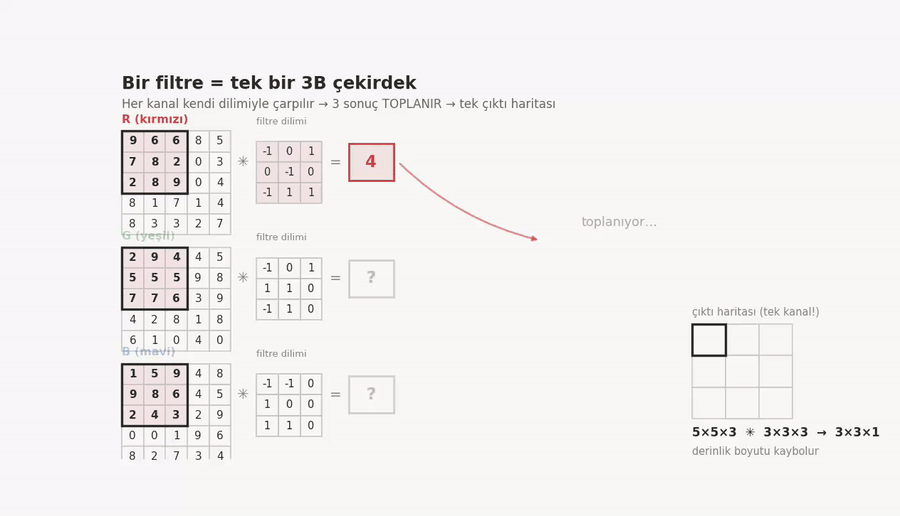

<sub>Derinlik kaybolur: 5×5×**3** ✳ 3×3×**3** → 3×3×**1**. Bir filtre = bir çıktı haritası.</sub>

### Kaç filtre varsa o kadar çıktı kanalı olur

Çıktının derinliğini girdinin derinliği değil, **filtre sayısı** belirler.

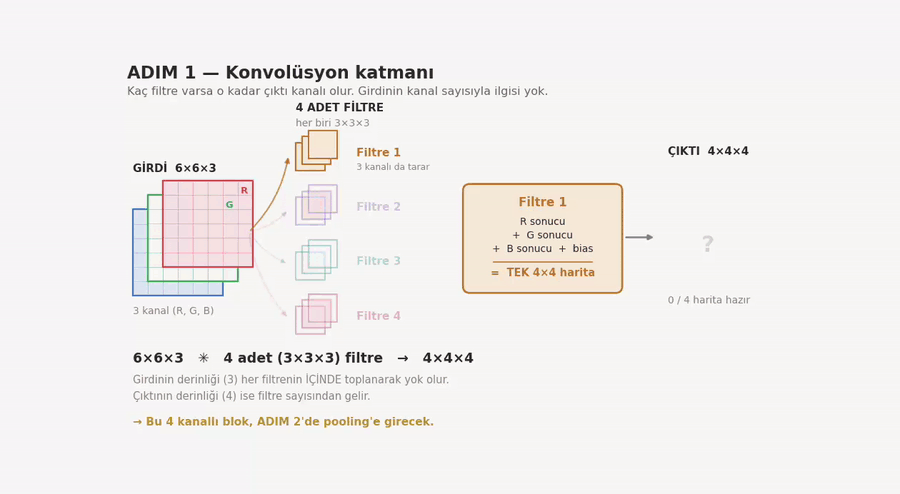

<sub>6×6×3 ✳ **4 adet** 3×3×3 filtre → 4×4×**4**. Bu 4 kanallı blok birazdan pooling'e girecek.</sub>

$$\text{çıktı} = \frac{\text{girdi} - \text{kernel} + 2\cdot\text{padding}}{\text{stride}} + 1$$

## 2.1 Stride (Adım Boyu)

Filtrenin her hamlede kaç piksel kayacağıdır. Büyütmek **çıktıyı küçültür**:
hesap ucuzlar ama ayrıntı kaybolur.

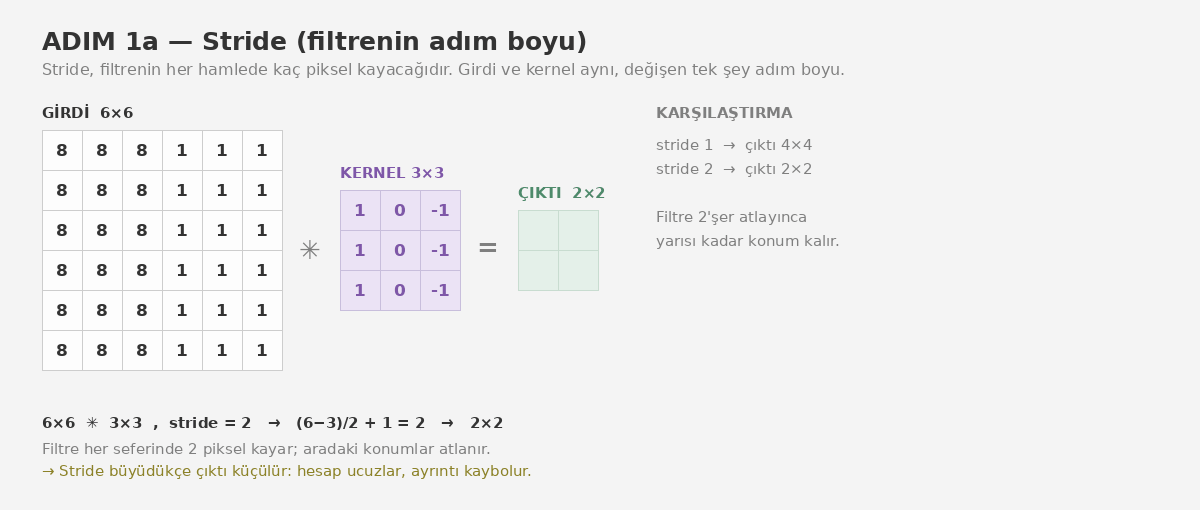

<sub>Aynı girdi, aynı kernel — değişen tek şey adım boyu. Çıktı 4×4 iken 2×2'ye düştü.</sub>

> **Özel durum:** 6×6 girdide stride 2 ile filtre 0. ve 2. sütunlardan başlar; **son sütun ve
> satır hiç taranmaz**. Keras varsayılanı `padding='valid'` taşan kısmı sessizce atar —
> boyutlar bölünmüyorsa veri kaybettiğinizi bilin.

## 2.2 Padding (Dolgulama)

Girdinin kenarlarına **0 eklemektir**. Amaç: çıktının boyutunu korumak.

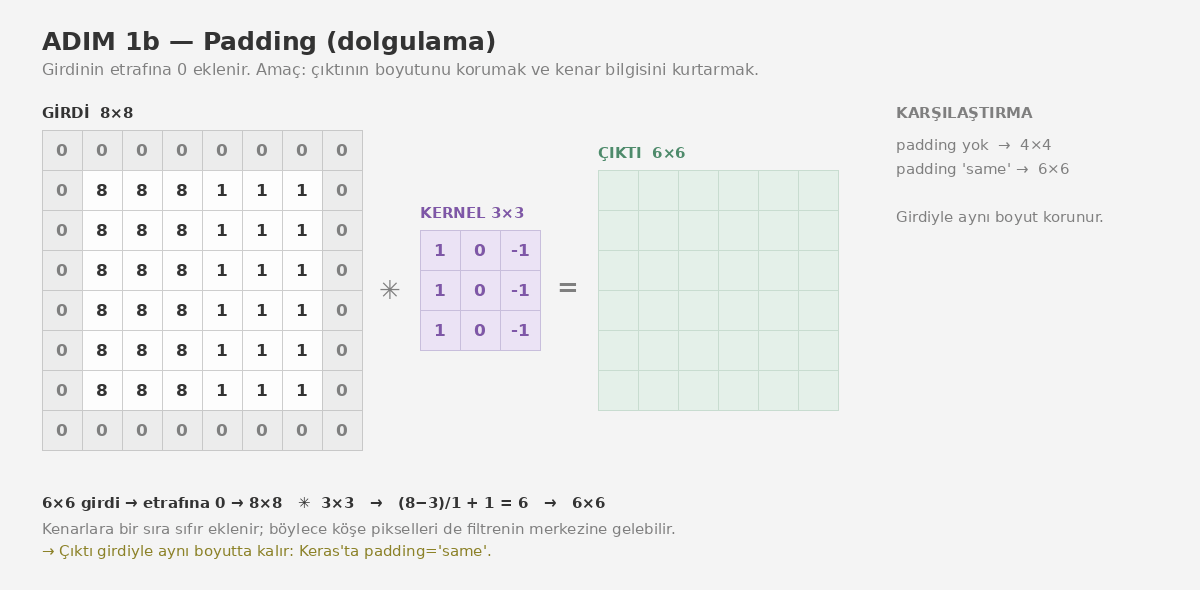

<sub>6×6 girdi 8×8'e dolduruldu → çıktı yine **6×6**.</sub>

**Neden kullanılır?**

| Durum | Sebep |
|---|---|
| Kenar bilgisi | Padding'siz köşe pikseli sadece 1 kez işlem görür, merkez piksel 9 kez — kenar bilgisi eziliyor |
| Segmentasyon (U-Net) | Çıktı maskesi girdiyle **aynı boyutta** olmak zorunda |
| Derin ağlar | Her katman 2 piksel yiyor; 20 katman sonra 224×224 tükenir |

Keras'ta iki seçenek var:

- `padding='valid'` → dolgu yok, boyut küçülür (varsayılan)
- `padding='same'` → boyut korunur (stride=1 iken)

> **Özel durum:** Sıfır dolgulama kenarda **yapay bir kenar** yaratır — GIF'te çıktının ilk
> sütunundaki `−16 / −24` değerleri gerçek bir kenar değil, eklenen sıfırların yan etkisidir.
> Bu yüzden bazı mimariler `reflect` / `replicate` dolgulama tercih eder.

### 2.3 Filtredeki sayıları kim yazıyor?

Kimse. Filtre ağırlıkları başlangıçta **rastgele** atanır (Keras varsayılanı
`glorot_uniform`; ReLU ile `he_normal` da yaygın) — sıfırla başlatılmaz, çünkü o zaman
bütün filtreler aynı kalır ve hiçbiri farklılaşmaz.

**Eğitimin amacı tam olarak bu ağırlıkları bulmaktır.** Geri yayılım her adımda her
filtre ağırlığını biraz günceller; sonunda bazı filtreler kenar bulmayı, bazıları doku
bulmayı kendiliğinden keşfeder.

### Düşünelim

- Evrişim katmanında amacımız nedir?
- Filtre hep 3×3 mi olmalı? 5×5 veya 7×7 ne kazandırır, ne kaybettirir?
- Boyutu küçültmek için stride mı, pooling mi? Hangisi ne zaman?

---

> **Ana akışa dönüyoruz.** Stride ve padding conv katmanının *ayarlarıydı*; örneğimizde
> ikisi de varsayılan (stride = 1, padding yok). Yani elimizde hâlâ **4×4×4** var.

`6×6×3` → **Conv (4 filtre)** → `4×4×4` → **MaxPool 2×2** → `2×2×4` → **Flatten** → `16`

---
# 3. Pooling Katmanı

Öznitelik haritasını **küçültür**: en × boy iner, **kanal sayısı aynı kalır**.
Hesap ucuzlar ve model küçük kaymalara karşı dayanıklı hale gelir.

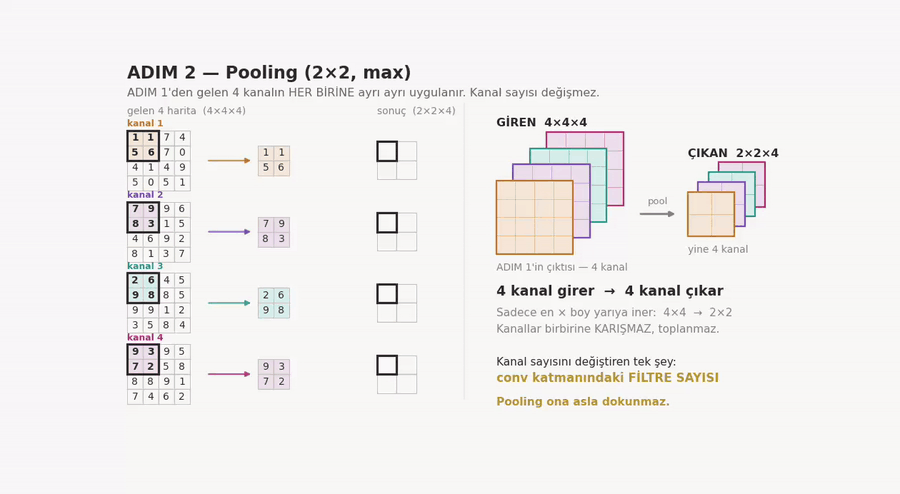

<sub>Conv'dan gelen **4×4×4** bloğun her kanalına ayrı ayrı 2×2 max pooling → **2×2×4**.
Kanal sayısını değiştiren tek şey conv'daki filtre sayısıdır; pooling ona dokunmaz.</sub>

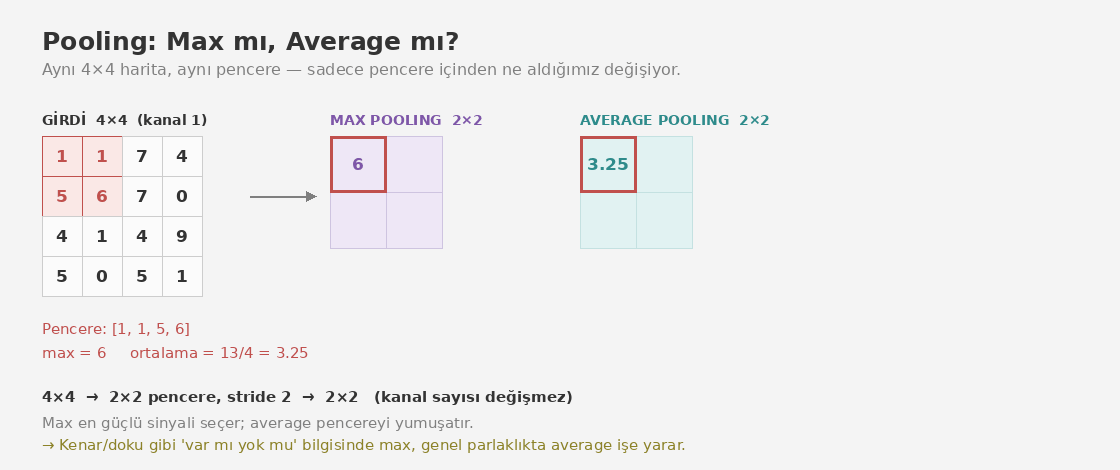

<sub>Aynı pencere, farklı özet: **max** en güçlü sinyali alır, **average** yumuşatır.</sub>

> **Özel durum:** `MaxPooling2D`'de stride varsayılanı **pencere boyutuna eşittir**
> (2×2 pencere → stride 2, pencereler örtüşmez). `Conv2D`'de ise stride varsayılanı **1**.
> İki katmanın varsayılanı farklı — sık karıştırılır.

### Düşünelim

- Boyut azalınca bilgi kaybı olur mu? Oluyorsa neden kabul ediyoruz?
- Max Pooling ve Average Pooling'i hangi durumda tercih ederiz?

---
# 4. Flatten Katmanı

Pooling'den çıkan **2×2×4** blok tek sıra sayıya serilir: **16 değer**. Bilgi aynı,
sadece şekli Dense katmanının istediği hale gelir.

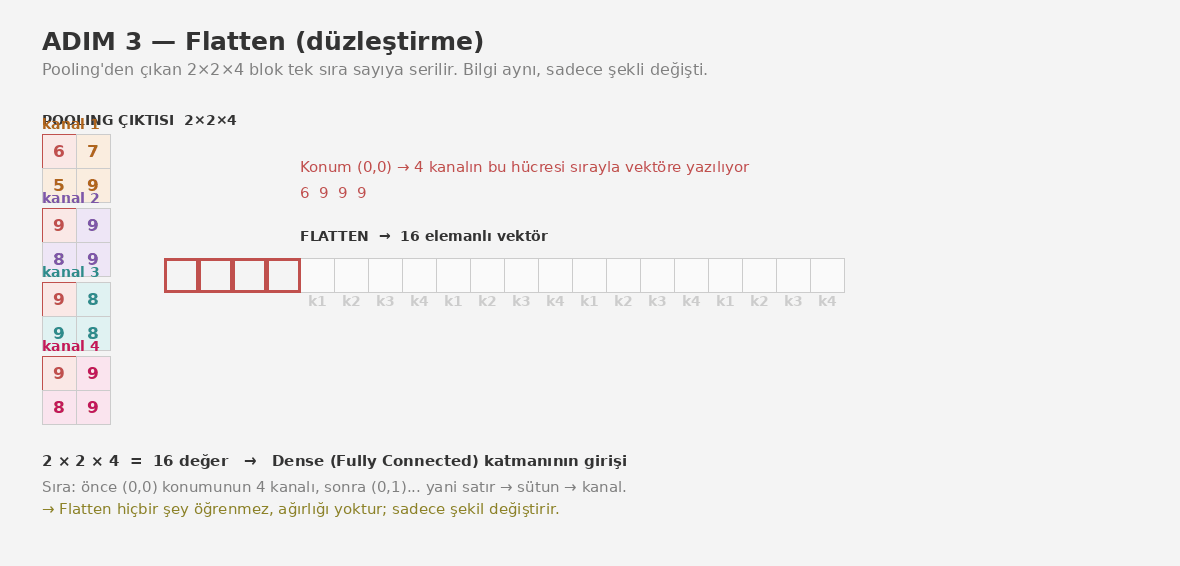

<sub>Sıra **satır → sütun → kanal**: önce (0,0) konumunun 4 kanalı, sonra (0,1)...
(TensorFlow/Keras `channels_last`). Flatten'ın ağırlığı yoktur, hiçbir şey öğrenmez.</sub>

---
---

# 5. Pretrained CNN Modelleri

> Buraya kadarı önceki dersin özetiydi. **Bugünkü konumuz buradan başlıyor.**

Pretrained model, **büyük bir veri kümesinde önceden eğitilmiş ve ağırlıkları
kaydedilmiş** bir ağdır. Sıfırdan başlamak yerine, birinin haftalarca GPU yakarak
öğrettiği "görme" yeteneğini indirip kendi problemimize uyarlarız.

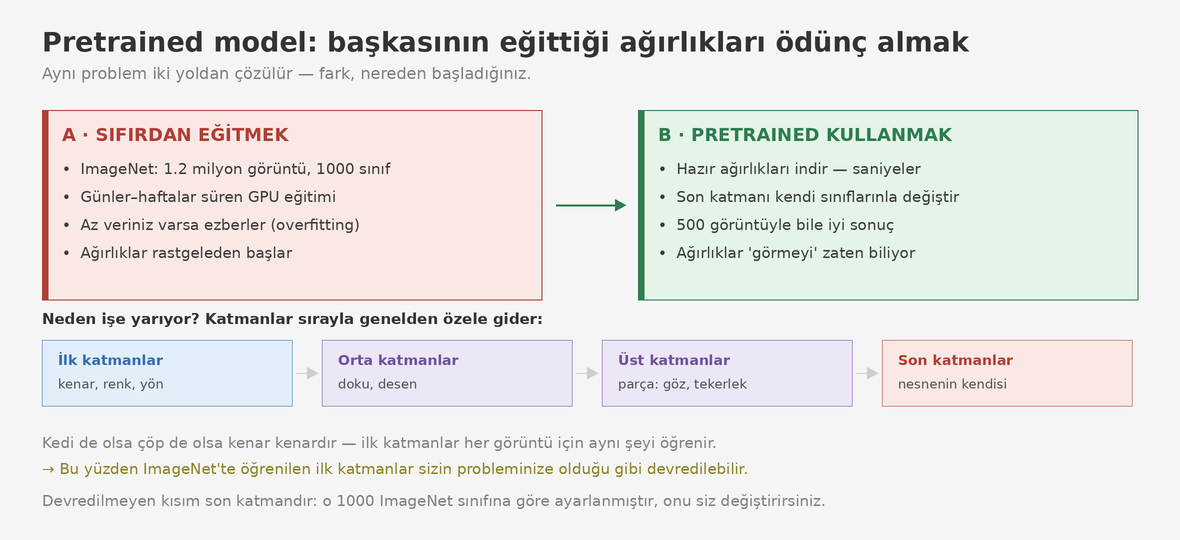

**Neden kullanıyoruz?**

| Kazanç | Ne demek? |
|---|---|
| **Kaynak ve zaman** | Haftalarca GPU eğitimi yerine saniyelerde indirilen ağırlıklar |
| **Performans** | Milyonlarca görüntüde öğrenilmiş öznitelikler, sizin küçük veri setinizden çok daha iyi genelleşir |
| **Özelleştirme** | Gövdeyi (backbone) tutup son katmanı kendi sınıflarınıza göre değiştirebilirsiniz |

**Nereden buluruz?**

| Kaynak | Ne için |
|---|---|
| **Keras Applications** | Görüntü sınıflandırma ve transfer learning için en pratiği — bu derste bunu kullanacağız |
| **TorchVision** | PyTorch tarafının karşılığı; veri setleri, model yapıları ve hazır ağırlıklar |
| **KerasCV** | Sadece model değil; katman, veri artırma, kayıp fonksiyonu — görüntü işlemeyi uçtan uca pipeline olarak ele alır |
| **OpenCV DNN** | Daha düşük seviye, performans odaklı; hazır modeli üretimde hızlı koşturmak için |
| **Hugging Face** | Merkezi model deposu; ağırlığı NLP'de ama görüntü ve nesne tespiti modelleri de artıyor |

> **Dikkat:** Hazır ağırlık indirmek, modelin sizin verinizde çalışacağı anlamına gelmez.
> ImageNet günlük nesnelerden oluşur; tıbbi görüntü veya uydu fotoğrafı gibi alanlarda
> kazanç azalır — yine de sıfırdan başlamaktan iyidir.

---
# 6. Mimarilerin Zaman Çizelgesi

Hangi hazır modeli seçeceğimize karar vermeden önce, seçeneklerin nereden geldiğine
bakalım. Her mimari bir soruna verilmiş bir cevap.

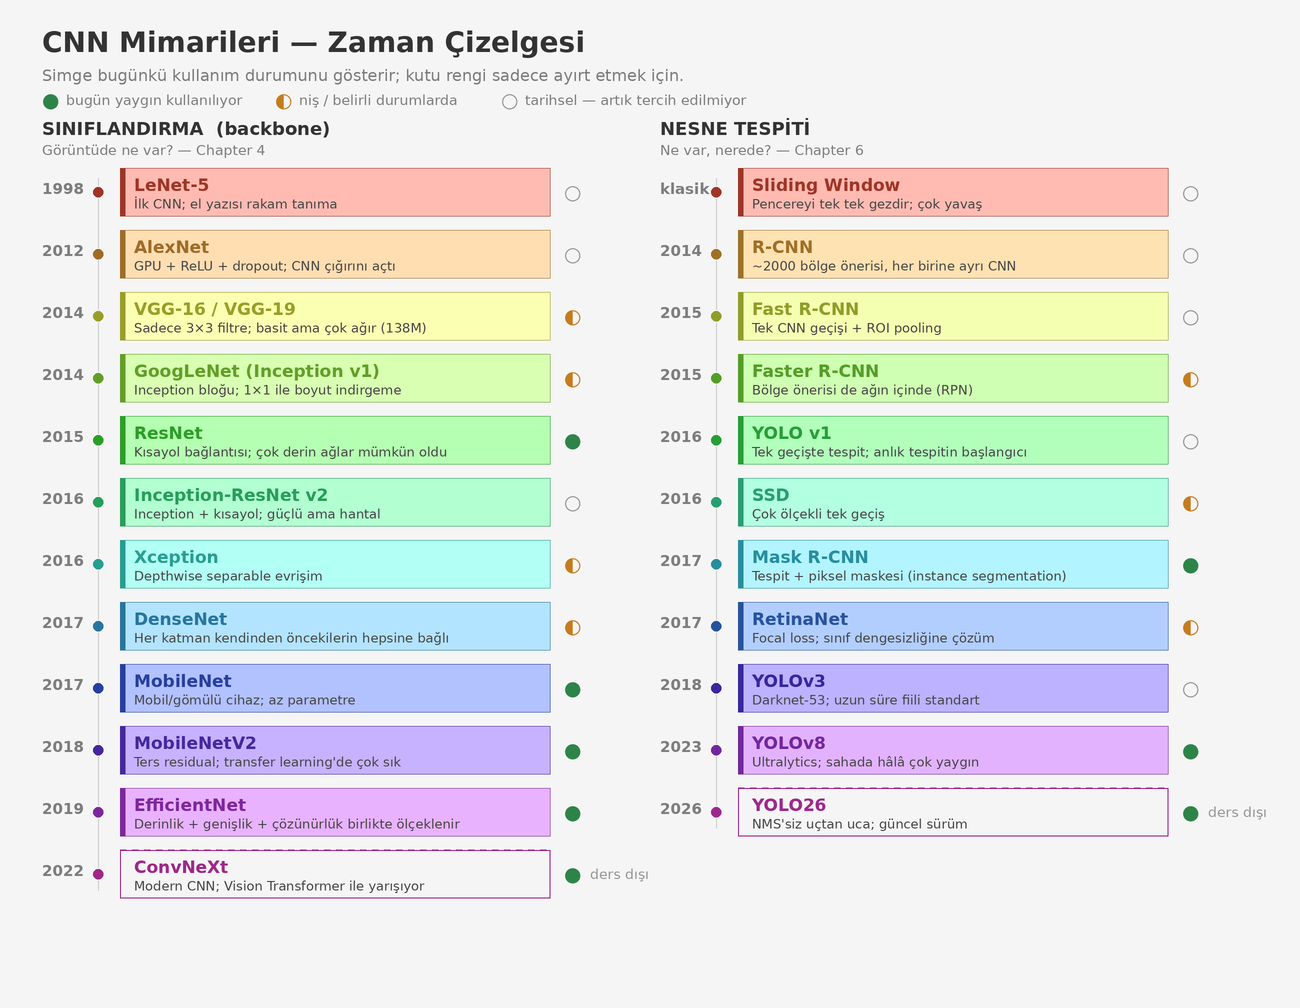

**Soldaki sütun** (sınıflandırma) iki dönemden geçti: önce modeller büyüdü ve derinleşti,
sonra yarış tersine döndü — **aynı doğruluğu daha az hesapla** verme yarışı. Bugün yaygın
olanlar (MobileNet, EfficientNet) bu ikinci dönemin ürünü.

**Sağdaki sütun** (nesne tespiti) da ikiye ayrılıyor: R-CNN ailesi **önce bölge önerir,
sonra sınıflandırır** — doğru ama yavaş. YOLO ve SSD ise **tek geçişte** yapar — hızlı.
Kameradan anlık tespit gereken işler tek geçişli tarafta bitti.

> **Derste YOLOv8 kullanacağız.** Ultralytics Ocak 2026'da YOLO26'yı yayınladı; kullanım
> şekli büyük ölçüde aynı, öğreneceğiniz mantık geçerli.

---
# 7. AlexNet (2012)

Derin öğrenmenin "işe yarıyor" dediği an. ImageNet 2012'yi kazandı ve ikinciyle
arasındaki farkı öyle açtı ki bütün alan yön değiştirdi.

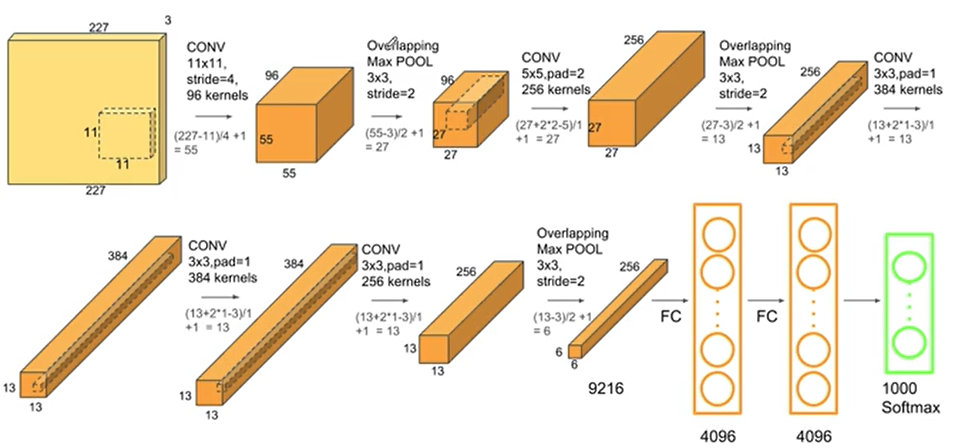

<sub>227×227×3 girdi → 5 evrişim + 3 tam bağlantı katmanı → 1000 sınıf softmax.</sub>

**Yapısı:** 8 ağırlıklı katman — **5 evrişim + 3 dense**, ~60 milyon parametre.
Büyük filtrelerle başlar (11×11, stride 4) ve hızla küçültür.

**Neyi değiştirdi?**

| Yenilik | Neden önemli |
|---|---|
| **ReLU** | Sigmoid/tanh yerine; eğitim birkaç kat hızlandı, derin ağ eğitilebilir hale geldi |
| **GPU ile eğitim** | Model iki GPU'ya bölünerek eğitildi — donanımın işin merkezine girdiği nokta |
| **Dropout** | Dense katmanlarda aşırı öğrenmeyi kırdı |
| **Veri artırma** | Kırpma ve yansıtma ile veri seti yapay olarak büyütüldü |
| **Örtüşen max pooling** | 3×3 pencere, stride 2 — pencereler üst üste biniyor |

**Bugün:** Doğrudan kullanılmıyor. 11×11 filtreler ve devasa dense katmanlar
verimsiz; yerini ResNet ve sonrası aldı. Tarihsel ve eğitsel değeri var.

---
# 8. VGG (Visual Geometry Group, 2014)

AlexNet'in dağınık filtre boyutlarını attı ve tek bir kurala indirdi:
**her yerde 3×3 evrişim, her blok sonunda 2×2 max pooling.**

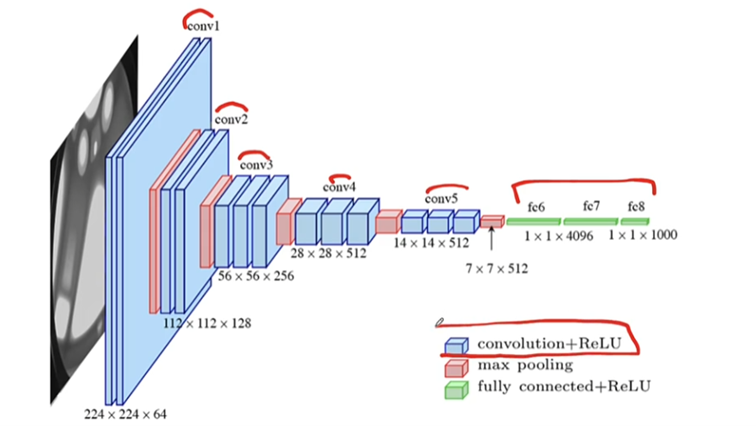

<sub>VGG-16: 224×224×3 → 5 evrişim bloğu (64 → 128 → 256 → 512 → 512 kanal) → 3 dense → 1000 sınıf.</sub>

**Yapısı:** VGG-16'da 16, VGG-19'da 19 ağırlıklı katman. Derinleştikçe uzamsal boyut
yarıya iner, kanal sayısı ikiye katlanır — bu desen bugün hâlâ standarttır.

**Öne çıkanları**

- **Standartlaştırılmış bloklar:** Sadece 3×3 filtre. Mimari homojen, okuması ve
  değiştirmesi kolay.
- **Ağırlık başlatma:** Xavier (Glorot) yöntemi — o dönem derin ağların yakınsaması
  için kritikti.
- **Aktivasyon:** Her evrişimden sonra ReLU.

**Küçük filtrenin mantığı:** Üst üste iki 3×3 filtre, tek bir 5×5 filtre kadar geniş bir
alanı görür — ama daha az parametreyle (18C² yerine 25C²) ve arada fazladan bir ReLU ile.
VGG'nin bütün fikri bu.

**Bedeli:** VGG-16 **~138 milyon parametre** (VGG-19 ~144M). Bunun yaklaşık **103
milyonu** tek bir yerde: `7×7×512 → 4096` tam bağlantı katmanı. Yani ağırlığın dörtte
üçü evrişimde değil, sondaki Dense katmanında birikiyor.

**Bugün:** Sınıflandırmada tercih edilmiyor — aynı doğruluğu ResNet çok daha az
parametreyle veriyor. Yine de basit ve öngörülebilir yapısı sayesinde stil transferi
gibi işlerde **öznitelik çıkarıcı** olarak hâlâ karşınıza çıkar.

---
# 9. ResNet (Residual Network, 2015)

VGG bize "derinleş" dedi ve derinleşince tıkandık. ResNet o tıkanmayı tek bir
fikirle açtı — ve o fikir bugün hâlâ her yerde.

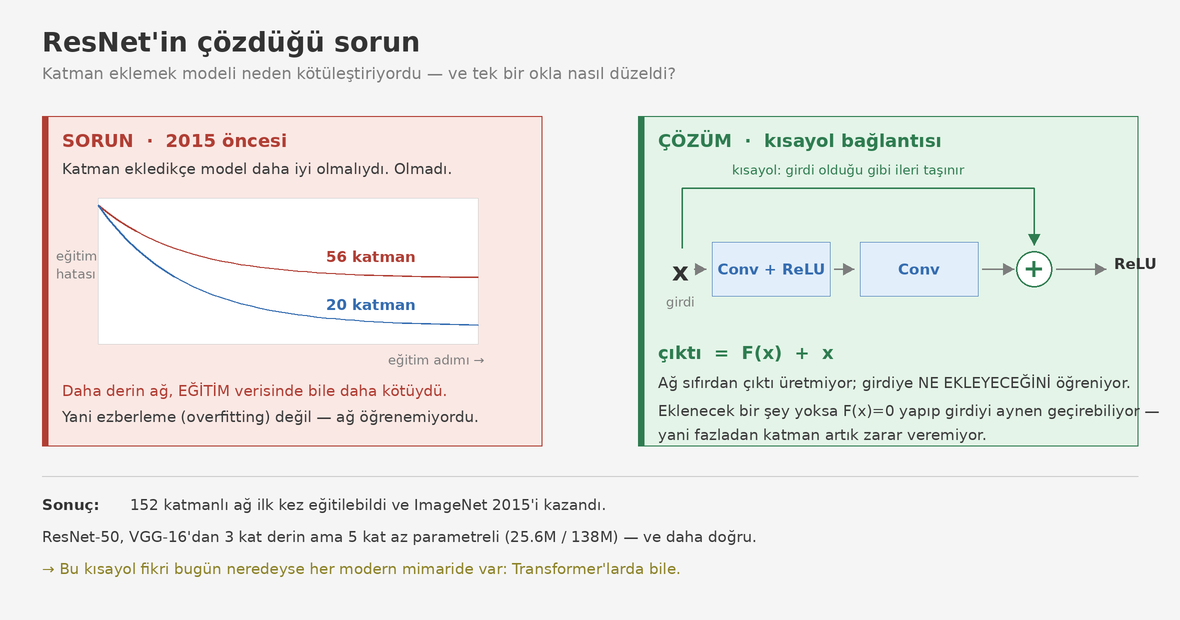

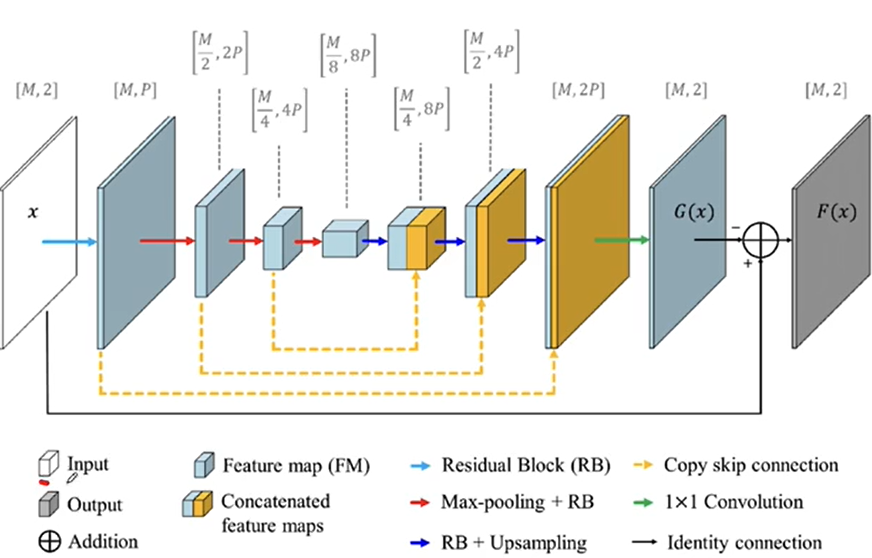

<sub>Residual bloklardan kurulu bir ağ. Mavi/kırmızı oklar residual blokları,
sarı kesikli oklar kopyalama-atlama bağlantılarını, en alttaki düz çizgi ise girdinin
doğrudan çıktıya eklenmesini (identity) gösteriyor.</sub>

**Yapısı:** ResNet-18, -34, -50, -101, -152 sürümleri var; sayı ağırlıklı katman
sayısıdır. Hepsi aynı yapı taşından kuruludur: birkaç evrişim katmanı ve onların
üzerinden atlayan bir kısayol.

VGG'den devraldığı desen aynı: **en × boy yarıya inerken kanal sayısı ikiye katlanır.**
Farkı, sondaki devasa Dense katmanları atıp yerine **Global Average Pooling** koyması —
VGG'yi şişiren 103 milyon parametre böylece ortadan kalkıyor.

| | VGG-16 | ResNet-50 |
|---|---|---|
| Ağırlıklı katman | 16 | 50 |
| Parametre | ~138M | ~25.6M |
| ImageNet doğruluğu | daha düşük | daha yüksek |

Derin sürümlerde blok içinde **1×1 → 3×3 → 1×1** sırası kullanılır: ilk 1×1 kanal
sayısını düşürür, pahalı 3×3 küçük veride çalışır, son 1×1 kanalı geri açar.
Aynı işi çok daha ucuza yapmanın yolu.

**Bugün:** Yeni bir işe başlarken en güvenli varsayılan. Basit, dayanıklı, her
kütüphanede hazır ağırlığı var. Nesne tespiti ve segmentasyon modellerinin çoğu da
omurga olarak ResNet kullanır.

> **Düşünelim:** Kısayol bağlantısı sayesinde fazladan katman "zarar veremiyor".
> Peki o zaman neden 1000 katmanlı ResNet yapmıyoruz?

---
---

# 10. Transfer Learning ve Fine Tuning

Buraya kadar mimarileri tanıdık. Şimdi asıl soruya geliyoruz: **bu hazır modelleri
kendi problemimizde nasıl kullanacağız?**

**Transfer learning**, önceden eğitilmiş bir modelin bilgisini farklı bir göreve
taşımaktır — bize bir *başlangıç noktası* verir.

**Fine tuning** ise o modeli bizim görevimizde en iyi sonucu verecek şekilde
*özelleştirmektir*.

İkisi aynı şey değil ama aynı işin iki adımıdır: önce transfer edersin, sonra ince ayar yaparsın.

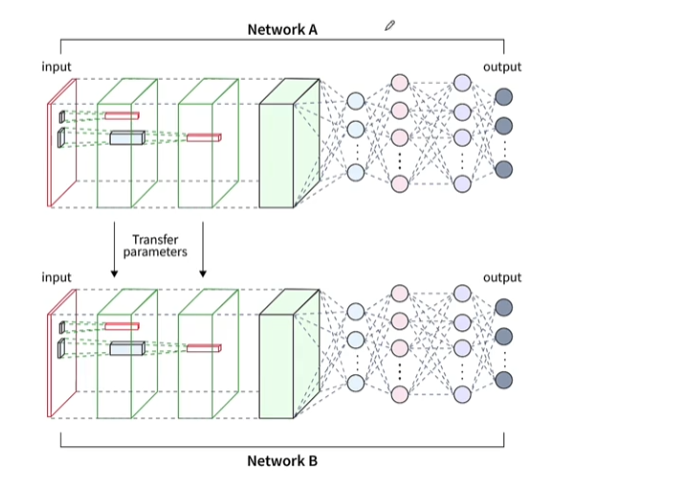

<sub>A ağının öğrendiği parametreler B ağına aktarılır; B kendi verisiyle devam eder.</sub>

## 10.1 Modeli ikiye ayırıyoruz: gövde ve kafa

Her sınıflandırma ağı iki parçadan oluşur:

- **Gövde (backbone):** evrişim katmanları. İşi öznitelik çıkarmak — kenar, doku, parça.
  Bu bilgi problemden bağımsızdır, **devredilebilir**.
- **Kafa (head):** son Dense katmanları. İşi karar vermek. ImageNet'in 1000 sınıfına
  göre ayarlıdır, **devredilemez**.

Yaptığımız şey basit: kafayı kesip atıyoruz, kendi kafamızı takıyoruz.

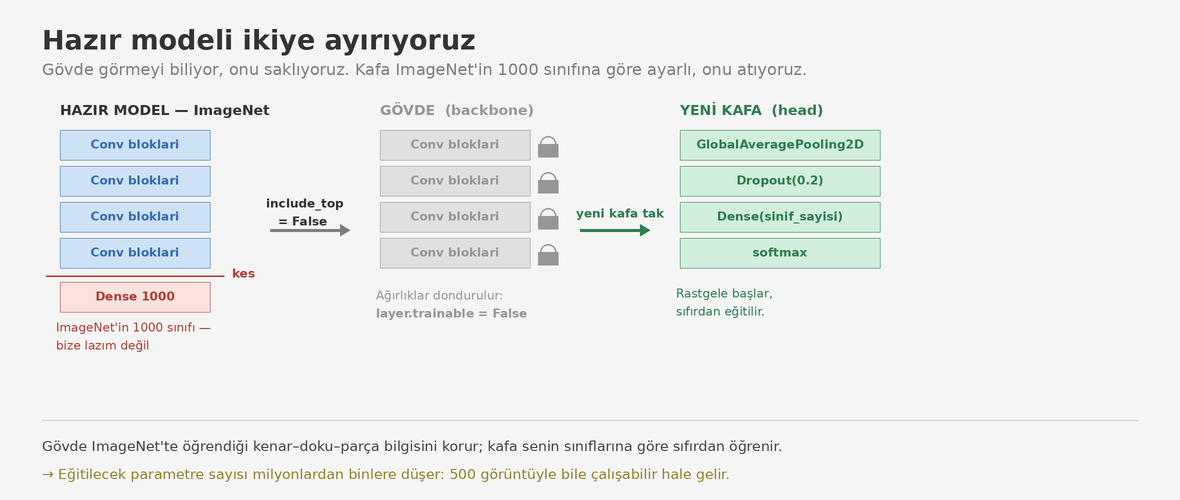

Keras'ta bu ayrımı yapan tek bir parametre var: **`include_top=False`**.
Modeli bu şekilde çağırdığında sadece gövdeyi indirirsin.

## 10.2 Hangi stratejiyi seçeceğim?

Cevabı iki soru belirler: **kaç görüntün var** ve **verin ImageNet'e ne kadar benziyor?**

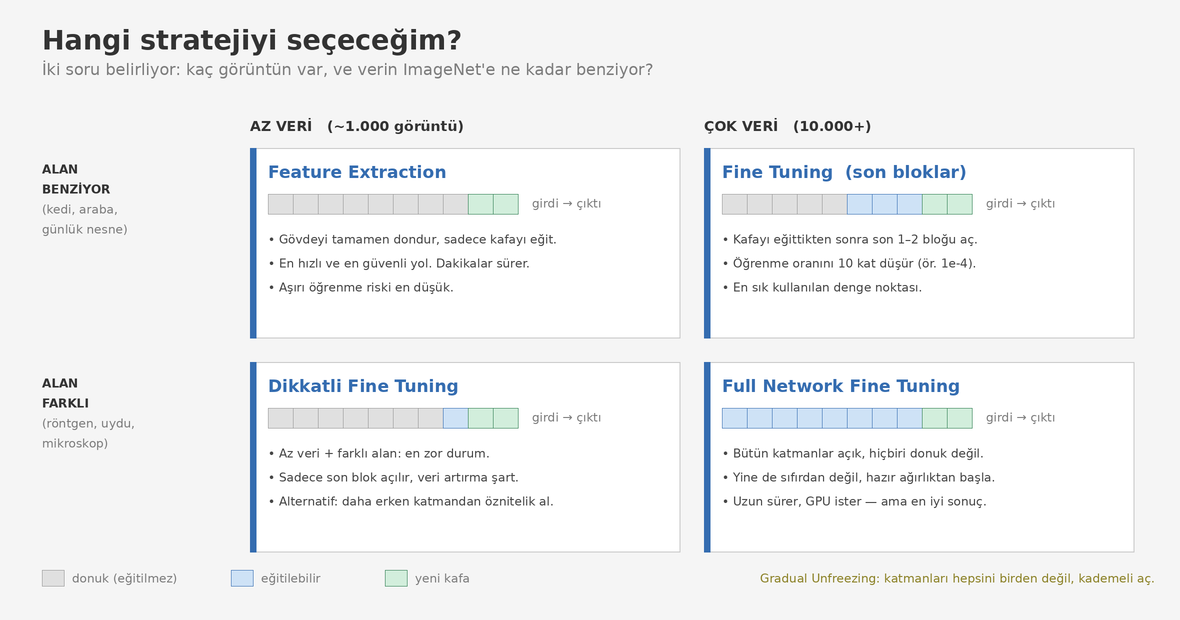

Kaynak Colab'daki dört teknik bu matrise şöyle oturuyor:

| Teknik | Ne yapar | Ne zaman |
|---|---|---|
| **Feature Extraction** | Gövde tamamen donuk, sadece kafa eğitilir | Az veri, benzer alan |
| **Frozen Layers** | Katmanların bir kısmı donuk, bir kısmı açık | Orta veri — en yaygın |
| **Full Network Fine Tuning** | Hiçbir katman donuk değil, hepsi eğitilir | Çok veri, farklı alan |
| **Gradual Unfreezing** | Katmanlar kademeli açılır, performans izlenerek | Zamanın varsa, en kontrollü |

## 10.3 Standart tarif — iki aşama

Pratikte neredeyse her zaman bu sırayla ilerlenir:

**1. Aşama — kafayı eğit**

1. Gövdeyi `include_top=False` ile yükle
2. `base_model.trainable = False` — gövdeyi tamamen dondur
3. Yeni kafayı tak: `GlobalAveragePooling2D → Dropout → Dense(sınıf_sayısı, softmax)`
4. Normal öğrenme oranıyla eğit (ör. `1e-3`), birkaç epoch

**2. Aşama — ince ayar**

5. `base_model.trainable = True`, sonra **son birkaç blok hariç** hepsini tekrar dondur
6. **Öğrenme oranını 10–100 kat düşür** (ör. `1e-5`)
7. Modeli yeniden derle (`compile`) — bu adım atlanırsa değişiklikler geçerli olmaz
8. Birkaç epoch daha eğit, doğrulama kaybını izle

**Tarifin iskeleti** — çalışan hali Bölüm 11'de, burada sadece şekli görelim:

```python
# ---------- 1. AŞAMA: kafayı eğit ----------
backbone = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

for layer in backbone.layers:                # gövde tamamen donuk
    layer.trainable = False

x = GlobalAveragePooling2D()(backbone.output)
x = Dropout(0.2)(x)
x = Dense(sinif_sayisi, activation="softmax")(x)
model = Model(inputs=backbone.input, outputs=x)

model.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_generator, validation_data=validation_generator, epochs=5)

# ---------- 2. AŞAMA: ince ayar ----------
for layer in backbone.layers[-30:]:          # son 30 katmanı aç
    if not isinstance(layer, BatchNormalization):   # ama BN'lere dokunma ← tuzak 4
        layer.trainable = True

model.compile(optimizer=Adam(1e-5),          # 100 kat düşük            ← tuzak 2
              loss="categorical_crossentropy", metrics=["accuracy"])    # ve YENİDEN DERLE
model.fit(train_generator, validation_data=validation_generator,
          epochs=10, initial_epoch=5)
```

Ön işleme (tuzak 1) bu kalıpta modelin içinde değil, veriyi okuyan tarafta:
`ImageDataGenerator(preprocessing_function=preprocess_input)`.

## 10.4 Dört tuzak

Bu dördü sessizce başarısız olur — hata mesajı almazsın, sadece sonuç kötü çıkar.

**1. Yanlış `preprocess_input`**

Her modelin kendi ön işlemesi var: MobileNetV2 girdiyi `[-1, 1]` aralığına çeker,
VGG16 ise BGR'ye çevirip ImageNet ortalamasını çıkarır. Modelin kendi
`preprocess_input` fonksiyonunu kullanmazsan model çöp üretir ama **hata vermez**.

**2. Yüksek öğrenme oranı**

İnce ayar aşamasında normal öğrenme oranını kullanırsan, açtığın katmanlar ilk birkaç
adımda ImageNet'te öğrendiklerini siler. Hazır ağırlıkla başlamanın hiçbir anlamı kalmaz.

**3. Yanlış sıra**

Gövdeyi kafadan önce açarsan: kafa henüz rastgele olduğu için büyük ve anlamsız
gradyanlar üretir, bunlar geri yayılıp gövdeyi bozar. **Önce kafa, sonra gövde.**

**4. BatchNormalization**

En sinsi olanı. `base_model.trainable = True` yaptığında BatchNormalization katmanları
da eğitilebilir hale gelir ve kendi hareketli ortalama/varyans istatistiklerini senin
küçük batch'ine göre güncellemeye başlar — bu, modelin öğrendiğini bozar.

İki çözüm var, hangisini kullanacağın modeli nasıl kurduğuna bağlı:

**a) Katmanları açarken BatchNormalization'ları dışarıda bırak** — Bölüm 11'de
kullandığımız yol:

```python
for layer in backbone.layers[-30:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True
```

**b) Gövdeyi bir katman gibi çağırıyorsan** `training=False` geç:

```python
x = base_model(inputs, training=False)
```

Bu kural **sadece BatchNormalization için** geçerlidir; diğer katmanlarda
"eğitilebilirlik" ile "eğitim/çıkarım modu" birbirinden bağımsızdır.

### Düşünelim

- 300 röntgen görüntüsüyle bir model kuracaksın. Matristeki hangi kutudasın?
- Fine tuning sonrası doğrulama kaybı artmaya başladı. Ne oldu, ne yaparsın?
- Gövdeyi hiç dondurmadan, doğrudan hepsini eğitsek ne kaybederiz?

---
---

# 11. Uygulama: Garbage Classification

Bölüm 10.3'teki iki aşamalı tarifi çalıştırıyoruz. Aynı veri, aynı tarif, iki farklı
gövde: **MobileNetV2** (hafif) ve **ResNet50** (ağır).

> **Başlamadan:** Menüden **Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU**
> seçin. CPU ile eğitim dakikalar değil, saatler sürer.

## 11.1 Veriyi indir

Veri seti GitHub'dan geliyor — Drive bağlamaya gerek yok, herkeste aynı şekilde çalışır.

In [ ]:
import os, zipfile, datetime, random
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
from glob import glob

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpu = tf.config.list_physical_devices("GPU")
print("GPU:", gpu if gpu else "YOK → Çalışma zamanı türünü T4 GPU yapın!")

URL = ("https://raw.githubusercontent.com/gorkenvm/Presentations/main/"
       "cnn2/veri/garbage_classification.zip")

zip_yolu = keras.utils.get_file("garbage_classification.zip", origin=URL, extract=False)
with zipfile.ZipFile(zip_yolu) as z:
    z.extractall("/content/veri")

dir_path = "/content/veri/Garbage classification"

print("\nVeri yolu:", dir_path)
toplam = 0
for sinif in sorted(os.listdir(dir_path)):
    n = len(os.listdir(os.path.join(dir_path, sinif)))
    toplam += n
    print(f"  {sinif:12s} {n:5d}")
print(f"  {'TOPLAM':12s} {toplam:5d}")

In [ ]:
# Birkaç örnek görüntüye bakalım
img_list = glob(os.path.join(dir_path, "**", "*.jpg"), recursive=True)
print(len(img_list), "görüntü bulundu")

plt.figure(figsize=(12, 3))
for i, yol in enumerate(random.sample(img_list, 6)):
    plt.subplot(1, 6, i + 1)
    plt.imshow(keras.utils.load_img(yol))
    plt.title(os.path.basename(os.path.dirname(yol)), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11.2 Veri hazırlığı ve artırma

`ImageDataGenerator` ile hem veriyi okuyoruz hem de **veri artırma** uyguluyoruz:
çevirme, kaydırma, yakınlaştırma. Böylece 2.500 görüntüden çok daha fazlasını görmüş oluyoruz.

> **Dikkat — Bölüm 10.4, tuzak 1:** Burada `rescale=1./255` **kullanmıyoruz**.
> Her hazır modelin kendi ön işlemesi var: MobileNetV2 girdiyi `[-1, 1]` aralığına
> çeker, ResNet50 ise BGR'ye çevirip ImageNet ortalamasını çıkarır. Yanlış ölçekleme
> hata vermez, sadece modeli sessizce kötüleştirir. O yüzden `preprocessing_function`
> olarak modelin **kendi** fonksiyonunu veriyoruz.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TARGET_SIZE = (224, 224)
BATCH_SIZE  = 32
SINIF_SAYISI = 6


def veri_akislari(preprocess_input):
    # Egitim: veri artirma VAR
    train = ImageDataGenerator(preprocessing_function=preprocess_input,
                               horizontal_flip=True,
                               vertical_flip=True,
                               shear_range=0.1,
                               zoom_range=0.1,
                               width_shift_range=0.1,
                               height_shift_range=0.1,
                               validation_split=0.2)

    # Dogrulama: artirma YOK, sadece on isleme
    val = ImageDataGenerator(preprocessing_function=preprocess_input,
                             validation_split=0.2)

    train_generator = train.flow_from_directory(dir_path,
                                                target_size=TARGET_SIZE,
                                                batch_size=BATCH_SIZE,
                                                class_mode="categorical",
                                                subset="training",
                                                seed=42)

    validation_generator = val.flow_from_directory(dir_path,
                                                   target_size=TARGET_SIZE,
                                                   batch_size=BATCH_SIZE,
                                                   class_mode="categorical",
                                                   subset="validation",
                                                   shuffle=False,      # sira sabit kalsin
                                                   seed=42)
    return train_generator, validation_generator


from keras.applications.mobilenet_v2 import preprocess_input as preprocess_mobilenetv2

train_generator, validation_generator = veri_akislari(preprocess_mobilenetv2)
SINIFLAR = list(train_generator.class_indices.keys())
print("Sınıflar:", SINIFLAR)

## 11.3 Gövdeyi tanıyalım — backbone, frozen, trainable

Eğitime başlamadan gövdeye bakalım: kaç katman var, kaçı eğitilebilir?
Bölüm 10.1'in somut karşılığı bu.

In [ ]:
from keras.applications.mobilenet_v2 import MobileNetV2

mobilenet_backbone = MobileNetV2(weights="imagenet",      # ImageNet agirliklari
                                 include_top=False,        # kafayi getirme
                                 input_shape=TARGET_SIZE + (3,))

print("Katman sayısı :", len(mobilenet_backbone.layers))
print("Parametre     :", f"{mobilenet_backbone.count_params():,}")

block_count = 0
for layer in mobilenet_backbone.layers:
    if isinstance(layer, layers.Conv2D) and "expand" in layer.name:
        block_count += 1
print("Mantıksal blok:", block_count)

print("\nSon 11 katman:")
for layer in mobilenet_backbone.layers[-11:]:
    print(f"  {layer.name:28s} {type(layer).__name__:22s} trainable={layer.trainable}")

In [ ]:
def parametre_ozeti(model, etiket):
    egitilebilir = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    donuk        = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
    print(f"{etiket:28s} eğitilebilir: {egitilebilir:>10,}   donuk: {donuk:>10,}")


parametre_ozeti(mobilenet_backbone, "1) İndirildiği hali")

# --- Feature Extraction: hepsini dondur ---
for layer in mobilenet_backbone.layers:
    layer.trainable = False
parametre_ozeti(mobilenet_backbone, "2) Tamamen dondurulmuş")

# --- Fine Tuning: son 11 katmani ac ---
# BatchNormalization'lari DISARIDA birakiyoruz — Bolum 10.4, tuzak 4
for layer in mobilenet_backbone.layers[-11:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True
parametre_ozeti(mobilenet_backbone, "3) Son 11 katman açık")

print("\nSon 11 katmanın durumu:")
for layer in mobilenet_backbone.layers[-11:]:
    print(f"  {layer.name:28s} trainable={layer.trainable}")

Üç satırdaki fark, Bölüm 10.2'deki üç stratejinin ta kendisi. BatchNormalization
katmanlarının `trainable=False` kaldığına dikkat edin — açsaydık, kendi hareketli
istatistiklerini bizim küçük batch'imize göre güncelleyip modeli bozacaklardı.

## 11.4 Aşama 1 — kafayı eğit

Gövde tamamen donuk, sadece yeni kafa öğreniyor.

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.metrics import AUC
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

EPOK_1 = 5        # canli derste kisa tutuldu; evde 15-20 deneyin
EPOK_2 = 5


def model_kur(backbone, sinif_sayisi=SINIF_SAYISI):
    x = GlobalAveragePooling2D()(backbone.output)
    x = Dropout(0.2)(x)
    x = Dense(sinif_sayisi, activation="softmax")(x)
    return Model(inputs=backbone.input, outputs=x)


# 1. asama: govde tamamen donuk
for layer in mobilenet_backbone.layers:
    layer.trainable = False

fine_tuning_model = model_kur(mobilenet_backbone)
parametre_ozeti(fine_tuning_model, "Tüm model (1. aşama)")

metrics = ["accuracy", AUC(name="auc", multi_label=True)]

fine_tuning_model.compile(optimizer=Adam(learning_rate=1e-3),
                          loss="categorical_crossentropy",
                          metrics=metrics)

early_stopping = EarlyStopping(monitor="val_loss", patience=5,
                               restore_best_weights=True, verbose=1)

start_time = datetime.datetime.now()
history_1 = fine_tuning_model.fit(train_generator,
                                  epochs=EPOK_1,
                                  validation_data=validation_generator,
                                  callbacks=[early_stopping])
sure_1 = datetime.datetime.now() - start_time
print("1. aşama süresi:", sure_1)

## 11.5 Aşama 2 — ince ayar

Üç şey aynı anda olmalı: katmanları aç, öğrenme oranını **100 kat** düşür,
modeli **yeniden derle**. Üçüncüsü atlanırsa hiçbir değişiklik geçerli olmaz.

In [ ]:
ACILACAK = 30       # son kac katman egitilecek

for layer in mobilenet_backbone.layers[-ACILACAK:]:
    if not isinstance(layer, layers.BatchNormalization):   # BN donuk kalsin
        layer.trainable = True

fine_tuning_model.compile(optimizer=Adam(learning_rate=1e-5),   # 100 kat dusuk
                          loss="categorical_crossentropy",
                          metrics=metrics)                      # ve YENIDEN DERLE

parametre_ozeti(fine_tuning_model, "Tüm model (2. aşama)")

start_time = datetime.datetime.now()
history_2 = fine_tuning_model.fit(train_generator,
                                  epochs=EPOK_1 + EPOK_2,
                                  initial_epoch=history_1.epoch[-1] + 1,
                                  validation_data=validation_generator,
                                  callbacks=[early_stopping])
sure_2 = datetime.datetime.now() - start_time
print("2. aşama süresi:", sure_2)

## 11.6 Sonuçlar

In [ ]:
def plot_training_history(h1, h2, baslik):
    def birlestir(ad):
        return h1.history[ad] + h2.history[ad]

    sinir = len(h1.history["accuracy"]) - 0.5
    sekil, (sol, sag) = plt.subplots(1, 2, figsize=(13, 4.4))

    sol.plot(birlestir("accuracy"), label="Training")
    sol.plot(birlestir("val_accuracy"), label="Validation")
    sol.axvline(sinir, color="red", ls="--")
    sol.set_title(f"{baslik} — Accuracy"); sol.set_xlabel("Epoch"); sol.legend()

    sag.plot(birlestir("loss"), label="Training")
    sag.plot(birlestir("val_loss"), label="Validation")
    sag.axvline(sinir, color="red", ls="--")
    sag.set_title(f"{baslik} — Loss"); sag.set_xlabel("Epoch"); sag.legend()

    plt.tight_layout()
    plt.show()


plot_training_history(history_1, history_2, "MobileNetV2")

val_loss, val_accuracy, val_auc = fine_tuning_model.evaluate(validation_generator, verbose=0)
print(f"MobileNetV2 → Loss: {val_loss:.4f}  Accuracy: {val_accuracy:.4f}  AUC: {val_auc:.4f}")

## Modeli iş başında görelim

Sayılar bir şey anlatır ama asıl ikna edici olan tahminleri görmektir.

In [ ]:
def tahminleri_goster(model, preprocess_input, baslik, n=8):
    yollar = random.sample(img_list, n)

    # Goruntuleri modelin bekledigi hale getir
    yigin = np.array([keras.utils.img_to_array(
        keras.utils.load_img(y, target_size=TARGET_SIZE)) for y in yollar])
    tahminler = model.predict(preprocess_input(yigin.copy()), verbose=0)

    plt.figure(figsize=(15, 7))
    for i, yol in enumerate(yollar):
        gercek   = os.path.basename(os.path.dirname(yol))
        tahmin   = SINIFLAR[int(np.argmax(tahminler[i]))]
        olasilik = float(np.max(tahminler[i]))
        dogru    = (tahmin == gercek)

        plt.subplot(2, 4, i + 1)
        plt.imshow(yigin[i].astype("uint8"))
        plt.title(f"{'DOGRU' if dogru else 'YANLIS'}  →  {tahmin}  %{olasilik*100:.0f}\n"
                  f"gerçek: {gercek}",
                  color="green" if dogru else "red", fontsize=10)
        plt.axis("off")

    plt.suptitle(baslik, fontsize=13)
    plt.tight_layout()
    plt.show()


tahminleri_goster(fine_tuning_model, preprocess_mobilenetv2, "MobileNetV2 — tahminler")

Yeşil başlıklar doğru, kırmızılar yanlış. Yüzde değeri modelin ne kadar emin olduğunu
gösteriyor — bazen yanlış cevaba da yüksek güven verebilir.

### Model nerede zorlanıyor?

In [ ]:
# Dogrulama kumesinin tamamini tahmin et (shuffle=False oldugu icin sira tutuyor)
validation_generator.reset()
olasiliklar = fine_tuning_model.predict(validation_generator, verbose=0)
tahmin_idx  = np.argmax(olasiliklar, axis=1)
gercek_idx  = validation_generator.classes

# Sinif basina dogruluk
print(f"{'Sınıf':12s} {'Doğru':>7s} {'Toplam':>7s} {'Oran':>8s}")
print("-" * 38)
for i, ad in enumerate(SINIFLAR):
    maske = gercek_idx == i
    dogru = int((tahmin_idx[maske] == i).sum())
    print(f"{ad:12s} {dogru:>7d} {int(maske.sum()):>7d} {dogru/max(maske.sum(),1):>8.2%}")

yanlis = np.where(tahmin_idx != gercek_idx)[0]
print(f"\nToplam {len(yanlis)} / {len(gercek_idx)} örnek yanlış bilindi")

In [ ]:
# Yanlis bilinen orneklerden birkacina bakalim
secim = yanlis[:8] if len(yanlis) >= 8 else yanlis

plt.figure(figsize=(15, 7))
for k, idx in enumerate(secim):
    yol = os.path.join(dir_path, validation_generator.filenames[idx])
    plt.subplot(2, 4, k + 1)
    plt.imshow(keras.utils.load_img(yol, target_size=TARGET_SIZE))
    plt.title(f"tahmin: {SINIFLAR[tahmin_idx[idx]]}  %{olasiliklar[idx].max()*100:.0f}\n"
              f"gerçek: {SINIFLAR[gercek_idx[idx]]}", color="red", fontsize=10)
    plt.axis("off")

plt.suptitle("Modelin yanıldığı örnekler", fontsize=13)
plt.tight_layout()
plt.show()

Bu tabloya bakarken şunu sorun: **hangi sınıf en kötü?** Genelde `trash` çıkar —
çünkü elimizde ondan sadece 137 görüntü var, diğerlerinden 400–600. Dengesiz veri
kümesinin bedeli bu.

Yanlış bilinen örneklere bakmak da öğreticidir: cam mı plastik mi karıştırılıyor?
İnsan gözüyle de zor olan örnekler mi?

Kırmızı kesikli çizgi ince ayarın başladığı yer — orada bir sıçrama bekliyoruz.
Doğrulama kaybı ince ayardan sonra **yükselmeye** başladıysa aşırı öğrenme var:
daha az katman açın ya da öğrenme oranını daha da düşürün.

## 11.7 Aynı tarif, farklı gövde: ResNet50

Tek değişen gövde ve onun ön işlemesi. Kodun geri kalanı birebir aynı.

In [ ]:
def tam_akis(backbone_kur, preprocess_input, ad, acilacak=ACILACAK):
    # Bir govde icin iki asamali tarifi bastan sona calistirir
    egitim, dogrulama = veri_akislari(preprocess_input)

    backbone = backbone_kur(weights="imagenet", include_top=False,
                            input_shape=TARGET_SIZE + (3,))
    for layer in backbone.layers:
        layer.trainable = False

    model = model_kur(backbone)
    model.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=metrics)

    t0 = datetime.datetime.now()
    h1 = model.fit(egitim, epochs=EPOK_1, validation_data=dogrulama, verbose=2)

    for layer in backbone.layers[-acilacak:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    model.compile(optimizer=Adam(1e-5), loss="categorical_crossentropy", metrics=metrics)
    h2 = model.fit(egitim, epochs=EPOK_1 + EPOK_2, initial_epoch=h1.epoch[-1] + 1,
                   validation_data=dogrulama, verbose=2)
    sure = datetime.datetime.now() - t0

    kayip, dogruluk, auc = model.evaluate(dogrulama, verbose=0)
    return {"ad": ad, "model": model, "backbone": backbone, "h1": h1, "h2": h2,
            "sure": sure, "dogruluk": dogruluk, "kayip": kayip, "auc": auc}


from keras.applications.resnet50 import ResNet50, preprocess_input as preprocess_resnet50

sonuc_resnet = tam_akis(ResNet50, preprocess_resnet50, "ResNet50")
plot_training_history(sonuc_resnet["h1"], sonuc_resnet["h2"], "ResNet50")

In [ ]:
sonuclar = [
    {"ad": "MobileNetV2", "backbone": mobilenet_backbone,
     "dogruluk": val_accuracy, "kayip": val_loss, "auc": val_auc,
     "sure": sure_1 + sure_2},
    sonuc_resnet,
]

print(f"{'Model':14s} {'Gövde param.':>14s} {'Accuracy':>10s} {'AUC':>8s} {'Süre':>10s}")
print("-" * 62)
for s in sonuclar:
    print(f"{s['ad']:14s} {s['backbone'].count_params():>14,} "
          f"{s['dogruluk']:>10.4f} {s['auc']:>8.4f} "
          f"{str(s['sure']).split('.')[0]:>10s}")

plt.figure(figsize=(6, 4))
plt.bar([s["ad"] for s in sonuclar], [s["dogruluk"] for s in sonuclar],
        color=["#4e8a6b", "#346cb0"])
for i, s in enumerate(sonuclar):
    plt.text(i, s["dogruluk"] + 0.02, f"{s['dogruluk']:.3f}", ha="center")
plt.ylabel("doğrulama doğruluğu"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()

### Düşünelim

- ResNet50 gövdesi MobileNetV2'nin ~10 katı parametreye sahip. Doğruluk farkı bunu
  haklı çıkarıyor mu?
- Modeli bir telefon uygulamasına koyacak olsanız hangisini seçerdiniz? Sunucuda?
- `ACILACAK` değerini 30'dan 60'a çıkarsak ne olur? Ya 5'e düşürsek?